# Анализ экспериментов в MLflow

Все эксперименты запускаются стадией `train` (`dvc repro`) и пишутся в MLflow Tracking
(`sqlite:///mlflow.db`). Здесь я собираю результаты через Python API MLflow
(`mlflow.search_runs`, загрузка артефактов и моделей, Model Registry) и выбираю модель.
Скриншоты того же самого в UI лежат в `reports/mlflow/`.

> Чтобы перезапустить ноутбук, нужен локальный `mlflow.db`. В git его нет (в нём абсолютные
> пути к артефактам), он создаётся при обучении: `dvc repro -f train`, около 4 минут.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from mlflow.tracking import MlflowClient
from sklearn.calibration import calibration_curve
from sklearn.metrics import f1_score, precision_score, recall_score

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))
os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"
from src.config import RAW_FEATURES, TARGET  # noqa: E402
from src.models.predict import load_model  # noqa: E402

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
FIG_DIR = ROOT / "reports" / "mlflow"
FIG_DIR.mkdir(parents=True, exist_ok=True)

mlflow.set_tracking_uri(f"sqlite:///{ROOT / 'mlflow.db'}")
client = MlflowClient()
experiment = mlflow.get_experiment_by_name("credit-default-pd")

runs = mlflow.search_runs([experiment.experiment_id])
is_parent = runs["tags.mlflow.parentRunId"].isna()
top, candidates = runs[is_parent].copy(), runs[~is_parent].copy()
print(f"Всего runs: {len(runs)}, экспериментов: {len(top)}, кандидатов поиска: {len(candidates)}")

Всего runs: 92, экспериментов: 6, кандидатов поиска: 86


## 1. Сводная таблица экспериментов

In [2]:
columns = {
    "params.experiment": "эксперимент",
    "tags.model_family": "алгоритм",
    "tags.feature_set": "признаки",
    "params.n_candidates": "кандидатов",
    "metrics.cv_roc_auc_mean": "CV AUC",
    "metrics.cv_roc_auc_std": "CV std",
    "metrics.test_roc_auc": "test AUC",
    "metrics.test_gini": "Gini",
    "metrics.test_ks": "KS",
    "metrics.test_precision": "Precision",
    "metrics.test_recall": "Recall",
    "metrics.test_f1": "F1",
    "metrics.test_brier": "Brier",
    "params.decision_threshold": "порог",
    "metrics.fit_time_sec": "время, с",
}
summary = (
    top[list(columns)]
    .rename(columns=columns)
    .sort_values("CV AUC", ascending=False)
    .reset_index(drop=True)
)
summary["время, с"] = summary["время, с"].round(1)
summary.round(4)

,эксперимент,алгоритм,признаки,кандидатов,CV AUC,CV std,test AUC,Gini,KS,Precision,Recall,F1,Brier,порог,"время, с"
0,gradient_boosting_fe,GradientBoostingClassifier,engineered,10,0.7889,0.0082,0.7794,0.5587,0.4276,0.5168,0.5573,0.5363,0.1348,0.2767,93.0
1,hist_gb_fe,HistGradientBoostingClassifier,engineered,20,0.7885,0.0085,0.7802,0.5604,0.4299,0.4997,0.5882,0.5404,0.1347,0.2653,7.8
2,random_forest_fe,RandomForestClassifier,engineered,12,0.7883,0.0088,0.7784,0.5567,0.4206,0.5181,0.5618,0.5391,0.1351,0.2932,96.6
3,hist_gb_raw,HistGradientBoostingClassifier,raw,20,0.7863,0.0070,0.7744,0.5489,0.4173,0.4928,0.5664,0.5270,0.1360,0.2673,7.3
4,logreg_fe,LogisticRegression,engineered,12,0.7655,0.0108,0.7581,0.5161,0.4017,0.5031,0.5566,0.5285,0.1903,0.5938,1.0
5,logreg_raw,LogisticRegression,raw,12,0.7256,0.0108,0.7191,0.4383,0.3631,0.5401,0.4570,0.4951,0.2059,0.5841,2.0


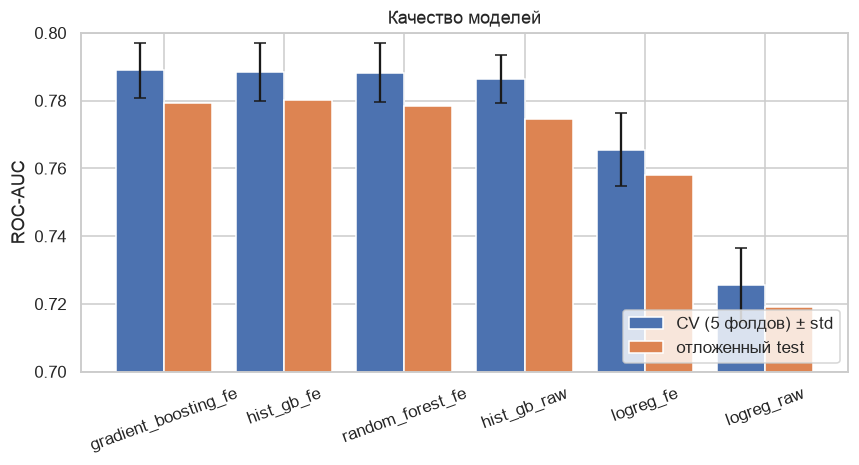

In [3]:
order = summary["эксперимент"]
x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - 0.2, summary["CV AUC"], 0.4, yerr=summary["CV std"], capsize=4, label="CV (5 фолдов) ± std")
ax.bar(x + 0.2, summary["test AUC"], 0.4, label="отложенный test")
ax.set_xticks(x, order, rotation=20)
ax.set(ylim=(0.70, 0.80), ylabel="ROC-AUC", title="Качество моделей")
ax.legend(loc="lower right")
fig.savefig(FIG_DIR / "roc_auc_by_experiment.png", bbox_inches="tight")
plt.show()

- Три ансамбля (градиентный бустинг, HistGradientBoosting, случайный лес) упираются в
  ROC-AUC ≈ 0.788–0.789 на CV, разница между ними 0.0006, а стандартное отклонение по фолдам
  0.008, то есть разница в пределах шума кросс-валидации. Формальный победитель по CV —
  `gradient_boosting_fe`.
- На test все модели теряют около 0.01 относительно CV, причём одинаково. Значит, выбор по CV не
  переобучился на конкретное разбиение, а test просто чуть «тяжелее».
- Логистическая регрессия заметно отстаёт, но с новыми признаками разрыв сокращается с 0.06 до 0.02.
- По времени разница огромная: HistGradientBoosting обучается за 8 секунд против полутора
  минут у GradientBoosting и RandomForest при том же качестве.

## 2. Что дал feature engineering

In [4]:
pairs = [("logreg_raw", "logreg_fe"), ("hist_gb_raw", "hist_gb_fe")]
auc = summary.set_index("эксперимент")[["CV AUC", "test AUC"]]
pd.DataFrame(
    {f"{fe} − {raw}": auc.loc[fe] - auc.loc[raw] for raw, fe in pairs}
).T.round(4)

,CV AUC,test AUC
logreg_fe − logreg_raw,0.0398,0.0389
hist_gb_fe − hist_gb_raw,0.0022,0.0057


Feature engineering дал +0.040 ROC-AUC логистической регрессии и лишь +0.002…0.006 бустингу.
Это ожидаемо: бустинг сам находит пороги вроде «просрочка ≥ 1 месяца» и взаимодействия
признаков с лимитом, а линейной модели нужно отдать их готовыми (число месяцев просрочки,
загрузку лимита). Для итоговой модели новые признаки почти ничего не меняют, зато делают её
устойчивее и понятнее при объяснении.

## 3. Подбор гиперпараметров (вложенные runs)

Каждый кандидат из `GridSearchCV` / `RandomizedSearchCV` записан вложенным run'ом со своими
параметрами и CV-метрикой. В UI MLflow по ним удобно строить parallel coordinates
(скриншот в `reports/mlflow/`), здесь — те же данные через API.

In [5]:
parent_name = top.set_index("run_id")["params.experiment"]
candidates["эксперимент"] = candidates["tags.mlflow.parentRunId"].map(parent_name)
candidates.groupby("эксперимент")["metrics.cv_roc_auc_mean"].agg(["count", "min", "max"]).round(4)

,count,min,max
эксперимент,,,
gradient_boosting_fe,10,0.7763,0.7889
hist_gb_fe,20,0.7836,0.7885
hist_gb_raw,20,0.7822,0.7863
logreg_fe,12,0.7636,0.7655
logreg_raw,12,0.7237,0.7256
random_forest_fe,12,0.7849,0.7883


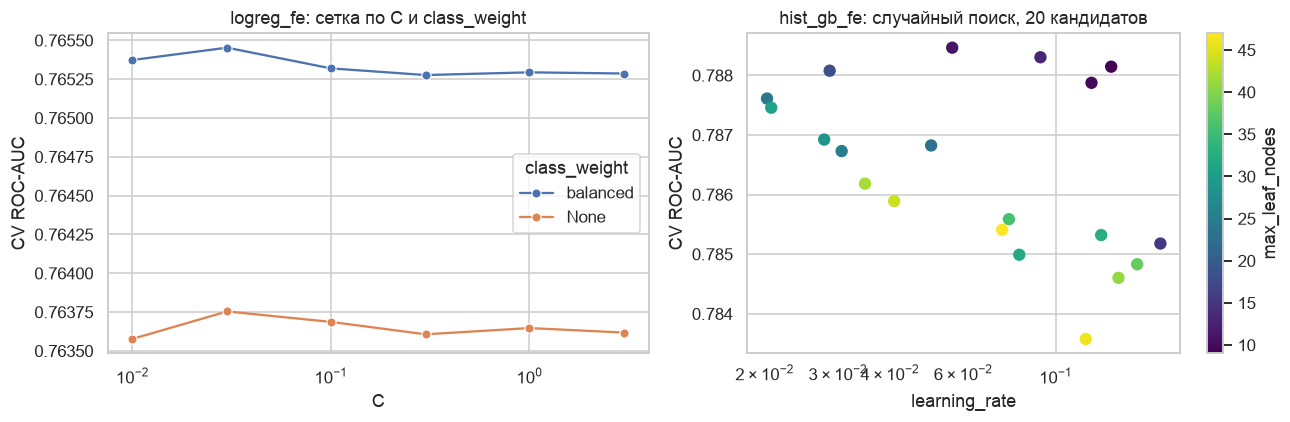

In [6]:
logreg = candidates[candidates["эксперимент"] == "logreg_fe"].copy()
logreg["C"] = logreg["params.C"].astype(float)
logreg["class_weight"] = logreg["params.class_weight"].fillna("None")

hgb = candidates[candidates["эксперимент"] == "hist_gb_fe"].copy()
for p in ["learning_rate", "max_leaf_nodes", "min_samples_leaf", "max_iter"]:
    hgb[p] = hgb[f"params.{p}"].astype(float)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=logreg, x="C", y="metrics.cv_roc_auc_mean", hue="class_weight", marker="o", ax=axes[0])
axes[0].set(xscale="log", ylabel="CV ROC-AUC", title="logreg_fe: сетка по C и class_weight")
sc = axes[1].scatter(hgb["learning_rate"], hgb["metrics.cv_roc_auc_mean"], c=hgb["max_leaf_nodes"],
                     cmap="viridis", s=50)
plt.colorbar(sc, ax=axes[1], label="max_leaf_nodes")
axes[1].set(xscale="log", xlabel="learning_rate", ylabel="CV ROC-AUC",
            title="hist_gb_fe: случайный поиск, 20 кандидатов")
plt.tight_layout()
fig.savefig(FIG_DIR / "hyperparameter_search.png", bbox_inches="tight")
plt.show()

- У логистической регрессии сила регуляризации `C` почти ни на что не влияет (разброс 0.002):
  при 24 тысячах объектов и ~40 признаках модели не на чем переобучаться.
  `class_weight="balanced"` даёт +0.002 AUC, но, как видно ниже, портит калибровку.
- У HistGradientBoosting лучше всего работают простые деревья (`max_leaf_nodes` ≈ 10–20), а большие
  деревья со множеством листьев проигрывают. Скорость обучения при этом важна меньше,
  потому что ранняя остановка сама подбирает число итераций.
- Весь разброс случайного поиска (0.784–0.789) меньше двух стандартных отклонений CV. Подбор
  гиперпараметров здесь даёт аккуратную, но небольшую прибавку, основной вклад вносят признаки
  и выбор семейства моделей.

## 4. Модель-чемпион: порог, калибровка, важность признаков

In [7]:
champion_run = top[top["tags.champion"] == "true"].iloc[0]
print("Чемпион:", champion_run["params.experiment"], champion_run["run_id"])
print("Лучшие гиперпараметры:")
param_cols = [c for c in top.columns if c.startswith("params.")]
skip = {"params.experiment", "params.add_features", "params.search", "params.n_candidates",
        "params.cv_folds", "params.seed"}
champion_run[[c for c in param_cols if c not in skip]].dropna()

Чемпион: gradient_boosting_fe 204d6bd68d70425f8b9ffc6a92d5fc7b
Лучшие гиперпараметры:


params.min_samples_leaf                       70
params.learning_rate         0.02226874072845983
params.decision_threshold                 0.2767
params.max_depth                               4
params.n_estimators                          207
params.subsample              0.8056937753654446
Name: 52, dtype: object

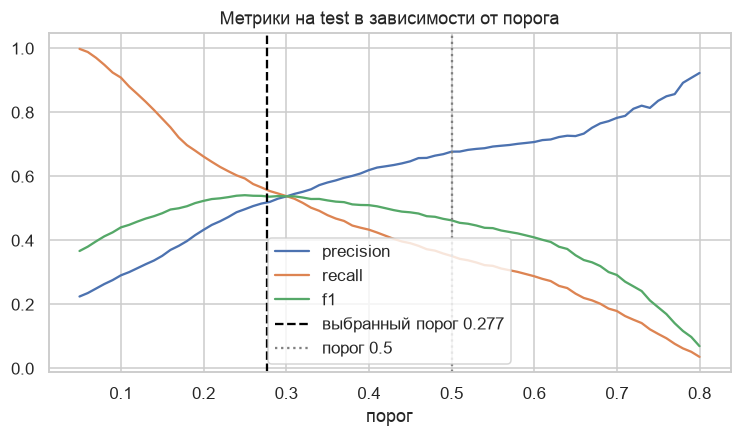

,threshold,precision,recall,f1
порог 0.5,0.500,0.677,0.351,0.463
выбранный порог,0.277,0.517,0.557,0.536


In [8]:
test = pd.read_csv(ROOT / "data/processed/test.csv")
champion = load_model(ROOT / "models/model.joblib")
proba = champion.predict_proba(test)

thresholds = np.linspace(0.05, 0.8, 76)
curves = pd.DataFrame({
    "threshold": thresholds,
    "precision": [precision_score(test[TARGET], proba >= t, zero_division=0) for t in thresholds],
    "recall": [recall_score(test[TARGET], proba >= t) for t in thresholds],
    "f1": [f1_score(test[TARGET], proba >= t) for t in thresholds],
})

fig, ax = plt.subplots(figsize=(8, 4))
for col in ["precision", "recall", "f1"]:
    ax.plot(curves["threshold"], curves[col], label=col)
ax.axvline(champion.threshold, color="black", ls="--", label=f"выбранный порог {champion.threshold:.3f}")
ax.axvline(0.5, color="grey", ls=":", label="порог 0.5")
ax.set(xlabel="порог", title="Метрики на test в зависимости от порога")
ax.legend()
fig.savefig(FIG_DIR / "threshold_tradeoff.png", bbox_inches="tight")
plt.show()


def metrics_at(t):
    pred = proba >= t
    return pd.Series({
        "threshold": t,
        "precision": precision_score(test[TARGET], pred),
        "recall": recall_score(test[TARGET], pred),
        "f1": f1_score(test[TARGET], pred),
    }).round(3)


pd.DataFrame({"порог 0.5": metrics_at(0.5), "выбранный порог": metrics_at(champion.threshold)}).T

Порог 0.277 подобран `TunedThresholdClassifierCV` на кросс-валидации по train, test в этом не
участвовал. По сравнению с порогом 0.5 recall вырос с 0.35 до 0.55, то есть модель находит
больше половины будущих дефолтов вместо трети. Precision при этом снизился с 0.68 до 0.52, а F1
вырос с 0.46 до 0.54. Если для банка пропуск дефолта дороже ложной тревоги (обычно так и есть),
порог можно сдвинуть ещё ниже. Для этого вместо F1 нужно задать функцию стоимости ошибок.

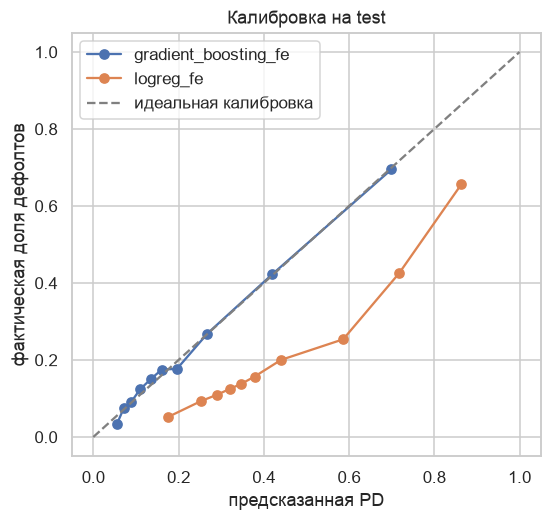

class_weight у logreg_fe: balanced


In [9]:
# Логрегрессию загружаем прямо из MLflow — так же её можно было бы взять в другом сервисе.
logreg_run_id = top.loc[top["params.experiment"] == "logreg_fe", "run_id"].iloc[0]
logreg_model = mlflow.sklearn.load_model(f"runs:/{logreg_run_id}/model")
proba_logreg = logreg_model.predict_proba(test[RAW_FEATURES])[:, 1]

fig, ax = plt.subplots(figsize=(5.5, 5))
for name, p in [(champion.meta["experiment"], proba), ("logreg_fe", proba_logreg)]:
    frac_pos, mean_pred = calibration_curve(test[TARGET], p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
ax.plot([0, 1], [0, 1], "--", color="grey", label="идеальная калибровка")
ax.set(xlabel="предсказанная PD", ylabel="фактическая доля дефолтов", title="Калибровка на test")
ax.legend()
fig.savefig(FIG_DIR / "calibration.png", bbox_inches="tight")
plt.show()
print("class_weight у logreg_fe:", top.loc[top["params.experiment"] == "logreg_fe", "params.class_weight"].iloc[0])

Это самое важное отличие моделей для PD-задачи. У бустинга точки лежат почти на диагонали: если
модель говорит «PD = 40%», то дефолтят действительно около 40% таких клиентов. Заметнее всего
модель ошибается в самой низкой группе риска (предсказывает 5.6%, по факту 3.5%). Логистическая
регрессия с `class_weight="balanced"` систематически завышает риск (при предсказанных 0.6 факт
около 0.25), потому что веса классов искусственно уравнивают доли. Ранжирование от этого не
страдает (ROC-AUC тот же), но использовать такие вероятности как PD для резервов или
ценообразования без перекалибровки нельзя. Это видно и по Brier score: 0.190 против 0.135.

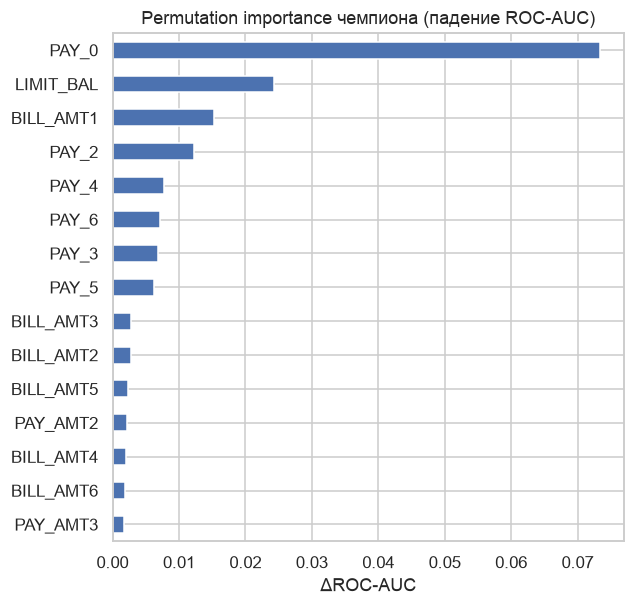

In [10]:
path = client.download_artifacts(champion_run["run_id"], "evaluation/feature_importance.csv")
importance = pd.read_csv(path, index_col=0)["importance"].sort_values()
fig, ax = plt.subplots(figsize=(6, 6))
importance.tail(15).plot.barh(ax=ax)
ax.set(title="Permutation importance чемпиона (падение ROC-AUC)", xlabel="ΔROC-AUC")
plt.show()

Permutation importance считается по 23 исходным полям: перемешиваем одно поле и смотрим,
насколько падает ROC-AUC. Главный признак — статус платежа в последнем месяце `PAY_0`, за ним
`LIMIT_BAL`. Интересно, что `BILL_AMT1` оказался третьим, хотя сам по себе почти
неинформативен (IV ≈ 0.01). Он важен через построенные из него признаки загрузки лимита
`UTIL_LAST`, `UTIL_MAX` и `BILL_TREND`: при перемешивании ломаются и они.

## 5. Model Registry

In [11]:
name = "credit-default-pd"
champion_version = client.get_model_version_by_alias(name, "champion")
versions = client.search_model_versions(f"name='{name}'")
print(f"Версий модели {name}: {len(versions)}")
print(f"Алиас champion -> версия {champion_version.version}, run {champion_version.run_id}")

Версий модели credit-default-pd: 1
Алиас champion -> версия 1, run 204d6bd68d70425f8b9ffc6a92d5fc7b


## Итог

- Для сервиса выбрана модель `gradient_boosting_fe`: лучшая по CV ROC-AUC, хорошо откалиброванная
  и с честно подобранным порогом. Она зарегистрирована в MLflow Model Registry как
  `credit-default-pd` с алиасом `champion` и сохранена в `models/model.joblib` (под DVC).
- На отложенной выборке: ROC-AUC 0.779, Gini 0.559, KS 0.428, Precision 0.517, Recall 0.557, F1 0.536.
- Если обучать придётся часто или на больших объёмах, `hist_gb_fe` даст то же качество в 12 раз
  быстрее. Это первый кандидат на замену.